# Reading parquet the hard way

Parquet is a cloud-native data format suitable for a variety of data types, including geospatial vector data. It is often described as being "column-oriented", as opposed to row-oriented like traditional databases and vector formats (though in reality parquet is really more of a hybrid format, one not strictly columnar).

The cloud-native aspect of parquet mainly comes down to two facets of its design:

* file metadata is consolidated at the end of a file, and can be read entirely in at most two requests
* the metadata contains enough information for clients to selectively read only chunks that may contain targeted rows

<div class="alert alert-block alert-info">
<b>Take note!</b>

This workshop series is designed for multiple locations around the world, and runs against Overture Maps data that is updated and repartitioned frequently. As such, this notebook has been written to be as generic as possible with regard to matched files/row groups/rows and the corresponding counts and geometry relationships. Depending on what location you are doing you might see some selection operations that don't fully make sense, like trying to further narrow down a set that has already been selected down to a single match.

When you see this happen: instead of thinking why don't we take the one match, think about what would need to be done if we had gotten more matches and we needed to filter futher. The query process in this notebook should be robust to any number of matches for each of the search layers, so treat each layer as a learning opportunity, even if the result doesn't materially change.
</div>

## Predicate pushdown

This "selective reading" is done by a process called "predicate pushdown". Predicate pushdown enables clients to skip reading potentially massive amounts of data by leveraging things like chunk statistics and chunk bloom filters to restrict reads to only those chunks that _may_ potentially contain target data.

Consider an example like this SQL statement:

```sql
SELECT temperature
FROM dataset
WHERE
  st_intersects(geom, AOI)
  AND snow_cover_percent > 0
  AND precipitation >= 10
  AND land_cover NOT IN ("rock", "urban")
```

Here we see the user requesting the `temperature` variable from `dataset` records that have:

* a geometry intersecting the AOI
* any snow cover
* some significant precipitation
* a non-impervious surface

Each of these conditions is called a predicate. Predicate pushdown means using predicates to filter what chunks to read from a file, or to even filter out whole files. File and chunk statistics provide a means of identifying files and chunks that cannot possibly have a record of interest per the query predicates, and skipping those. Of those remaining, bloom filters can provide another efficient check to eliminate chunks that cannot possibly contain target records. What chunks are left are then read and filtered by the client application using the actual values prior to returning the requested data.

Note the language "cannot possibly contain" is used here specifically: we never want to miss a matching record, so we use techniques that give us means of eliminating chunks with certainty that they will not contain a record of interest. These techniques come with the trade off that false positives can occur: we can rarely know that a chunk _does_ have a target record. Sometimes we then read chunks without target records, because that is the only way to ensure they do not have what we are looking for.

Generally though, predicate pushdown is an effective means of eliminating a large amount of data without having to read anything but metadata.

## The exercise

To get a deeper understanding of parquet and how it works, we're going to examine the [Overture Maps Buildings dataset](https://docs.overturemaps.org/guides/buildings). We will find the geometry for the building we're in for this workshop, the
Sheraton Grand Sacramento Hotel.

This exercise is perhaps a bit contrived, because we'll start with a rough geometry for the building that we traced from aerial imagery in exercise 1, but the principles we'll be demonstrating are applicable generally for clients wanting to read from parquet, and will show how that process works in some detail. Key to the process will be a focus on using predicate pushdown with geometries, and how we can use less expensive bounding box operations to more efficiently eliminate chunks and records before turning to more expensive real-geometry comparisons.

### The `por-que` library

To facilitate the learning experience, we'll use the author's custom python parquet parsing library, called `por-que`. This library is different from other, more efficient parsing libraries like `pyarrow`, in that it is designed for the educational experience. A core feature is the parsing of the entire file metadata, data page metadata, and byte structure of the file, which it exposes to users, unlike other tools that keep them hidden away as internal details.

`por-que` can export the entire parsed structure to JSON, which can then be loaded, visualized, and explored with the [`ver-por-que` web application](https://teotl.dev/ver-por-que/). We'll see all of this in action through the exercise.

But first, let's get some prep out of the way.

### A persistent byte cache

We are going to be making a _lot_ of HTTP range requests in this exercise. Under the hood, `por-que` reads bytes through a transport library called `hctef`, which can persist every byte range it fetches to a size-bounded disk cache. With the cache enabled, re-running a cell reads from local disk instead of hitting the network again.

We configure the cache with environment variables before using `por-que`. We can also safely mark the cache immutable (skipping revalidation requests) because Overture release paths are versioned: the bytes at any given URL never change.

In [1]:
import os

os.environ.setdefault('HCTEF_CACHE_DIR', str(os.path.abspath('.hctef-cache')))
os.environ.setdefault('HCTEF_CACHE_MAX_BYTES', str(4 * 2**30))  # 4 GiB
os.environ.setdefault('HCTEF_CACHE_IMMUTABLE', '1')

'1'

Now the necessary imports.

In [2]:
import asyncio
import hashlib
import json
import time
import urllib.request

from dataclasses import dataclass
from importlib.metadata import version
from pathlib import Path
from typing import Any, Self
from urllib.parse import urljoin

import aiohttp

from devtools import pprint
from hctef.aio.aiohttp_transport import AiohttpTransport
from IPython.display import Pretty
from por_que import AsyncHttpFile, FileMetadata, ParquetFile
from shapely import (
    from_geojson as shapely_from_geojson,
    from_wkb as shapely_from_wkb,
    intersection,
)

We'll also define a helper function for zipping async iterators together, which we'll use later.

In [3]:
async def azip(*iterators):
    """This is a silly zip implementation for async iterators that
    assumes equal length. Don't copy this. It's not robust."""
    _iter = iter(iterators)
    first, rest = next(_iter), list(_iter)
    async for val in first:
        yield (val, *[await anext(iterator) for iterator in rest])

And a couple helpers to handle some result caching and progress updates we'll run later in the exercise.

In [4]:
def parquet_progress():
    status = display(Pretty('starting...'), display_id=True)
    last = 0.0

    def callback(phase, done, total):
        nonlocal last
        now = time.monotonic()
        if done < total and now - last < 0.2:
            return
        last = now
        status.update(Pretty(f'{phase}: {done:_} of {total:_}'))

    return callback


@dataclass
class MetadataCacheEntry:
    url: str
    metadata: FileMetadata
    size: int

    @classmethod
    def from_path(cls, path: Path) -> Self:
        cached = json.loads(path.read_text())
        return cls(
            url=cached['url'],
            metadata=FileMetadata.model_validate(cached['metadata']),
            size=cached['size'],
        )

    def to_path(self, path: Path) -> None:
        path.write_text(
            json.dumps(
                {
                    'url': self.url,
                    'size': self.size,
                    # `by_alias=True` is load-bearing: a few fields on the
                    # statistics model are aliased (the deprecated `min`/`max`
                    # are `min_`/`max_` in Python, to dodge the builtins), and
                    # `model_validate` below reads the aliases. Dumping without
                    # it writes names the loader then ignores, so those fields
                    # come back `None` with no error at all. This is what
                    # `por-que`'s own `to_json()` does for the same reason.
                    'metadata': self.metadata.model_dump(mode='json', by_alias=True),
                },
            ),
        )


class FileMetadataCache:
    # bump when the on-disk layout changes, so old entries miss
    # instead of loading as something subtly different
    FORMAT = '2'

    def __init__(self) -> None:
        self.dir = Path('.metadata-cache')
        self.dir.mkdir(exist_ok=True)
        self.version = version('por-que')

    def get_path(self, url: str) -> Path:
        sha = hashlib.sha1(url.encode())
        sha.update(self.version.encode())
        sha.update(self.FORMAT.encode())
        return self.dir / f'{sha.hexdigest()}.json'

    def check(self, url: str) -> MetadataCacheEntry | None:
        try:
            return MetadataCacheEntry.from_path(self.get_path(url))
        except Exception:  # noqa: BLE001
            # any error loading the cache we just
            # ignore as though there is no cache
            return None

    def set(self, contents: MetadataCacheEntry) -> None:
        contents.to_path(self.get_path(contents.url))


class BulkLoader:
    """Base for loading many files at once.

    Subclasses say what to do with one file by implementing `_load()`.
    This class owns the two things that have to be shared across every
    file in a run, no matter what that per-file work is: one HTTP
    transport, and one progress line.
    """

    #: past-tense verb for the progress line, e.g. '3 of 42 files scanned'
    verb = 'loaded'

    def __init__(
        self,
        total: int,
        columns: list[str] | None = None,
        concurrency: int = 100,
    ) -> None:
        self.done = 0
        self.total = total
        self.columns = columns
        self.concurrency = concurrency
        self._display = None
        self._transport = None
        self.progress()

    async def __aenter__(self) -> Self:
        # one transport, so every file shares a single connection pool
        # instead of each paying its own handshake; the pool size is what
        # bounds how many files we can be connecting to at any one time
        self._transport = AiohttpTransport(
            session_kwargs={
                'connector': aiohttp.TCPConnector(limit=self.concurrency),
            },
        )
        return self

    async def __aexit__(self, *_) -> None:
        if self._transport:
            await self._transport.close()
        self._transport = None

    def progress(self) -> None:
        msg = Pretty(
            f'{self.done} of {self.total} files {self.verb}',
        )
        if not self._display:
            self._display = display(
                msg,
                display_id=True,
            )
        else:
            self._display.update(msg)

    def open(self, url: str) -> AsyncHttpFile:
        """Open a file on the loader's shared transport.

        Going through here rather than constructing an `AsyncHttpFile`
        directly is the whole point of the class: a bare
        `AsyncHttpFile(url)` builds its own transport, and so its own
        connection pool, which is exactly what we're avoiding.
        """
        return AsyncHttpFile(url, transport=self._transport)

    async def _load(self, url: str) -> Any:
        raise NotImplementedError

    async def load_url(self, url: str) -> Any:
        result = await self._load(url)
        self.done += 1
        self.progress()
        return result


class BulkFileMetadataLoader(BulkLoader):
    verb = 'scanned'

    def __init__(self, *args, **kwargs) -> None:
        super().__init__(*args, **kwargs)
        self.cache = FileMetadataCache()

    async def _load(self, url: str) -> tuple[FileMetadata, int]:
        cached = self.cache.check(url)

        if cached:
            # a cache hit needs no network at all, so it never touches the pool
            return cached.metadata, cached.size

        async with self.open(url) as f:
            metadata = await FileMetadata.from_reader(f, columns=self.columns)
            size = f.size
            self.cache.set(
                MetadataCacheEntry(
                    url=url,
                    metadata=metadata,
                    size=size,
                ),
            )

        return metadata, size


class BulkParquetFileLoader(BulkLoader):
    verb = 'parsed'

    def __init__(self, row_groups: dict[str, list[int]], **kwargs) -> None:
        # the column projection is the same for every file, but the row
        # group projection is not, so this loader is constructed from the
        # whole url -> row group indexes mapping and looks up each url as
        # it goes. That mapping is also the work list, so it sets the total.
        super().__init__(len(row_groups), **kwargs)
        self.row_groups = row_groups

    async def _load(self, url: str) -> tuple[ParquetFile, int]:
        async with self.open(url) as f:
            pf = await ParquetFile.from_reader(
                f,
                url,
                columns=self.columns,
                row_groups=self.row_groups[url],
            )
            # read before the file closes; it costs nothing by
            # this point, as opening the file already learned the size
            return pf, f.size

And we'll define a bounding box model, which we will be able to use for all of the bounding box operations in this exercise. Note that we could have used an existing model from a library, but by implementing our own we can see how simple the bounding box operations are.

In [5]:
@dataclass(slots=True, frozen=True)
class BBox:
    xmin: int | float
    ymin: int | float
    xmax: int | float
    ymax: int | float

    def intersects(self, other: Self) -> bool:
        # touching counts as intersecting: a prefilter must never drop a candidate
        return (
            other.xmin <= self.xmax
            and self.xmin <= other.xmax
            and other.ymin <= self.ymax
            and self.ymin <= other.ymax
        )

    @classmethod
    def from_linestring(cls, linestring: list[list[int | float]]) -> Self:
        xmin = float('inf')
        ymin = float('inf')
        xmax = float('-inf')
        ymax = float('-inf')

        try:
            for x, y in linestring:
                xmin = min(xmin, x)
                ymin = min(ymin, y)
                xmax = max(xmax, x)
                ymax = max(ymax, y)
        except (TypeError, ValueError) as e:
            # what a non-coordinate-pair element raises when it fails to unpack
            raise ValueError('Failed to extract bbox') from e

        return cls(xmin, ymin, xmax, ymax)

Lastly, we'll define the geometry we'll be using for this exercise, and we'll use it with our `BBox` class to construct its bounding box. Again, this is the same polygon we delineated in exercise 1.

In [6]:
geom = json.loads("""{
  "type": "Polygon",
  "coordinates": [
    [
      [
        -121.4902746,
        38.5793368
      ],
      [
        -121.4904459,
        38.5789284
      ],
      [
        -121.4895781,
        38.5787015
      ],
      [
        -121.4894185,
        38.5790713
      ],
      [
        -121.4894417,
        38.579119
      ],
      [
        -121.4902746,
        38.5793368
      ]
    ]
  ]
}""")
geom

{'type': 'Polygon',
 'coordinates': [[[-121.4902746, 38.5793368],
   [-121.4904459, 38.5789284],
   [-121.4895781, 38.5787015],
   [-121.4894185, 38.5790713],
   [-121.4894417, 38.579119],
   [-121.4902746, 38.5793368]]]}

In [7]:
geom_bbox = BBox.from_linestring(geom['coordinates'][0])
geom_bbox

BBox(xmin=-121.4904459, ymin=38.5787015, xmax=-121.4894185, ymax=38.5793368)

## Overture Maps parquet data

Overture Maps has a number of datasets available in parquet format, including the building footprints dataset we'll be using for this exercise. All are distributed from both AWS and Azure using their respective object storage services.

Overture cuts a new release of the data roughly monthly, and, notably, **old releases get deleted**. Hardcoding a release path is a great way to have a notebook that stops working after a month or two (ask me how I know). What we want instead is a way to discover the latest release, and the files within it, dynamically.

### The Overture STAC catalog

Overture publishes a [STAC](https://stacspec.org/) catalog describing every release at `https://stac.overturemaps.org/catalog.json`. STAC (SpatioTemporal Asset Catalog) is a specification for describing geospatial data with JSON metadata; if you've used a STAC API before, note this is the other flavor: a **static catalog**, nothing but plain JSON files linked to each other, served over HTTP. We have no search endpoint: a client navigates by fetching a JSON document, inspecting its `links` array, and following `href`s of interest. That makes a static catalog itself a nice example of cloud-native thinking: it's just files, any dumb object store can host it, and the client does the work.

The links use **relative** `href`s (e.g. `./2026-06-17.0/catalog.json`), so we resolve each against the URL of the document we found it in, just like a browser resolves relative links in HTML.

Let's define some small helpers to fetch JSON documents, then grab the root catalog and take a look.

In [8]:
STAC_ROOT_URL = 'https://stac.overturemaps.org/catalog.json'


def url_read(url: str) -> bytes:
    with urllib.request.urlopen(url) as response:
        return response.read()


def url_read_json(url: str) -> dict[str, Any]:
    return json.loads(url_read(url))

In [9]:
stac_root = url_read_json(STAC_ROOT_URL)

pprint(stac_root)

{
    'type': 'Catalog',
    'id': 'Overture Releases',
    'stac_version': '1.1.0',
    'description': 'All Overture Releases',
    'links': [
        {
            'rel': 'root',
            'href': 'https://stac.overturemaps.org/catalog.json',
            'type': 'application/json',
            'title': 'Overture Releases',
        },
        {
            'rel': 'self',
            'href': 'https://stac.overturemaps.org/catalog.json',
            'type': 'application/json',
        },
        {
            'rel': 'child',
            'href': 'https://stac.overturemaps.org/2026-09-23.0/catalog.json',
            'type': 'application/json',
            'title': '2026-09-23.0 Overture Release',
        },
        {
            'rel': 'child',
            'href': 'https://stac.overturemaps.org/2026-09-23.1/catalog.json',
            'type': 'application/json',
            'title': '2026-09-23.1 Overture Release',
        },
        {
            'rel': 'child',
            'href': 'htt

The root catalog has a `child` link per release. Notice the extra `latest` marker Overture puts on the newest release's link: that is our dynamic version pin. Let's follow it down the tree. The releases are partitioned by theme, then by type within the theme, so from the release catalog we follow the `buildings` theme child, and from there the `building` type child, which is a STAC collection.

In [10]:
latest_link = next(link for link in stac_root['links'] if link.get('latest'))
latest_release_url = urljoin(STAC_ROOT_URL, latest_link['href'])
latest_release_url

'https://stac.overturemaps.org/2026-10-21.0/catalog.json'

In [11]:
release_catalog = url_read_json(latest_release_url)

buildings_link = next(
    link
    for link in release_catalog['links']
    if link['rel'] == 'child' and link['title'] == 'buildings'
)
buildings_url = urljoin(latest_release_url, buildings_link['href'])
buildings_catalog = url_read_json(buildings_url)

building_link = next(
    link
    for link in buildings_catalog['links']
    if link['rel'] == 'child' and link['title'] == 'building'
)
building_collection_url = urljoin(buildings_url, building_link['href'])
building_collection = url_read_json(building_collection_url)

building_collection

{'type': 'Collection',
 'stac_version': '1.1.0',
 'stac_extensions': ['https://stac-extensions.github.io/table/v1.2.0/schema.json',
  'https://schemas.portolan-sdi.org/incubating/partition/v1.0.0/schema.json'],
 'id': 'building',
 'title': 'building',
 'description': "Overture's building collection",
 'license': 'ODbL-1.0',
 'extent': {'spatial': {'bbox': [[-180.0,
     -84.29460906982422,
     179.9996795654297,
     83.09400939941406],
    [-180.0, -84.29460906982422, -85.67642211914062, 13.96748161315918],
    [-85.67667388916016,
     -33.812294006347656,
     -80.42048645019531,
     13.967358589172363],
    [-80.4207534790039,
     -33.66915512084961,
     -78.17540740966797,
     -2.091052532196045],
    [-80.42088317871094,
     -2.092092514038086,
     -78.17481231689453,
     13.575301170349121],
    [-169.54232788085938,
     15.479231834411621,
     -93.19983673095703,
     17.64483070373535],
    [-93.20013427734375,
     14.030993461608887,
     -91.4957046508789,
     17

The `building` collection has an `item` link for every parquet file in the dataset. How many are there?

In [12]:
item_links = [link for link in building_collection['links'] if link['rel'] == 'item']
len(item_links)

512

Wow, that's a lot of files! But it is not unexpected: this is a worldwide building footprints dataset, so it has _a lot_ of records (we'll see exactly how many in a bit). To make it more efficient to access a subset of the dataset, Overture partitions the rows into smaller files. So we have a ton of data here, how will we ever find the record for which we are searching?

First we need the item documents themselves: one small JSON file per parquet file. Fetching hundreds of documents one at a time would be annoyingly slow: each request would wait for the previous one to finish, paying the full network round trip every time. Instead, we can use parallelism to speed this up, making the requests for each file all at the same time. We can do this by using async python, creating coroutines up front, each of which fetches one of the files. Then we run the coroutines concurrently with `asyncio.gather`, so the round trips overlap. Keep this pattern in mind; we'll use it again shortly for something much bigger.

We'll define a slightly different helper to fetch json, one that is async.

In [13]:
async def get_json(session: aiohttp.ClientSession, url: str) -> dict[str, Any]:
    async with session.get(url) as response:
        response.raise_for_status()
        return await response.json()


async with aiohttp.ClientSession() as session:
    items = await asyncio.gather(
        *[
            get_json(session, urljoin(building_collection_url, link['href']))
            for link in item_links
        ],
    )

pprint(items[0])

{
    'type': 'Feature',
    'stac_version': '1.1.0',
    'stac_extensions': [
        'https://stac-extensions.github.io/storage/v2.0.0/schema.json',
        'https://stac-extensions.github.io/alternate-assets/v1.2.0/schema.json',
        'https://stac-extensions.github.io/file/v2.1.0/schema.json',
    ],
    'id': '00000',
    'geometry': {
        'type': 'Polygon',
        'coordinates': [
            [
                [
                    -180.0,
                    -84.29460906982422,
                ],
                [
                    -85.67642211914062,
                    -84.29460906982422,
                ],
                [
                    -85.67642211914062,
                    13.96748161315918,
                ],
                [
                    -180.0,
                    13.96748161315918,
                ],
                [
                    -180.0,
                    -84.29460906982422,
                ],
            ],
        ],
    },
    'bbox

Each item describes one parquet file: where it lives (the `assets`, with an HTTPS URL for each of AWS and Azure), plus some properties about it, and even the bounding box of everything in the file. We'll read from AWS; let's pull out the HTTPS S3 URLs for every file.

In [14]:
parquet_urls = [item['assets']['aws']['href'] for item in items]
parquet_urls[:3]

['https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00000-85375c54-5dfb-57c7-b21d-8b5e5245ad06-c000.zstd.parquet',
 'https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00001-25a868c6-9ddc-5e1c-8e0e-8286ae2005d9-c000.zstd.parquet',
 'https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00002-06f46650-1c0e-59b8-a12a-1645f91912bc-c000.zstd.parquet']

## Loading one of these files using `por-que`

`por-que` exposes three key classes, each of which we'll be using throughout the rest of this exercise:

* `AsyncHttpFile`
* `FileMetadata`
* `ParquetFile`

The first of these, `AsyncHttpFile`, is a helper class that can open an HTTP(S) URL and expose it as a readable filelike object (and is actually re-exported from `hctef`; this is what we set the caching env vars for at the beginning). We need this to allow the other two classes to do their parsing of the parquet files over HTTP.

`FileMetadata` is a class that represents the block of metadata at the end of a parquet file. This metadata includes both file level information, like the schema, and chunk level metadata via row groups and their column chunks. Passing a readable filelike object into `FileMetadata.from_reader()` will parse the metadata object from said file.

`ParquetFile` is a class that represents the entire physical and logical structure of a parquet file. This includes `FileMetadata`, but also all data page locations and metadata. `ParquetFile` and its nested `DataPage` objects allow reading data from the file. `ParquetFile.from_reader()`, similar to above, will parse the full structure and metadata from a passed in readable filelike object.

Let's see how we can use `AsyncHttpFile` with `ParquetFile` and some of what the latter exposes. Note that creating the `ParquetFile` instances has to make many random reads within the file, so this is not a fast process, especially over the network (though thanks to the byte cache we set up at the top, re-running it, if required, is nearly instant).

Because these parses can take a while, `por-que` accepts a `progress` callback: it calls the function with the current phase of the parse and how far along it is. We can use that with an updating IPython display to get a live one-line status without spewing output. Let's make a small factory so every slow parse in this notebook can have its own status line, because then we have some insight to what's happening when things are taking awhile.

In [15]:
async with AsyncHttpFile(parquet_urls[0]) as hf:
    pf = await ParquetFile.from_reader(
        hf,
        parquet_urls[0],
        progress=parquet_progress(),
    )

column-chunks: 5_760 of 5_760

In [16]:
pprint(pf.metadata.schema_root)

SchemaRoot(
    element_type=<SchemaElementType.ROOT: 'root'>,
    name='schema',
    full_path='',
    start_offset=532468813,
    byte_length=13,
    definition_level=0,
    repetition_level=0,
    num_children=24,
    children={
        'id': SchemaLeaf(
            element_type=<SchemaElementType.COLUMN: 'column'>,
            name='id',
            full_path='id',
            start_offset=532468826,
            byte_length=15,
            definition_level=1,
            repetition_level=0,
            type=<Type.BYTE_ARRAY: 6>,
            repetition=<Repetition.OPTIONAL: 1>,
            converted_type=<ConvertedType.UTF8: 0>,
            type_length=None,
            scale=None,
            precision=None,
            field_id=None,
            logical_type=StringTypeInfo(
                logical_type=<LogicalType.STRING: 1>,
            ),
            list_semantics=None,
        ),
        'names': SchemaGroup(
            element_type=<SchemaElementType.GROUP: 'group'>,
      

In [17]:
pprint(pf.metadata.row_groups[0])

RowGroup(
    start_offset=532469936,
    byte_length=5113,
    column_chunks={
        'id': ColumnChunk(
            file_offset=919890,
            metadata=ColumnMetadata(
                start_offset=532469944,
                byte_length=137,
                type=<Type.BYTE_ARRAY: 6>,
                encodings=[
                    <Encoding.PLAIN: 0>,
                    <Encoding.RLE: 3>,
                    <Encoding.RLE_DICTIONARY: 8>,
                ],
                path_in_schema='id',
                codec=<Compression.ZSTD: 6>,
                num_values=43935,
                total_uncompressed_size=1807617,
                total_compressed_size=919886,
                data_page_offset=528453,
                index_page_offset=None,
                dictionary_page_offset=4,
                statistics=ColumnStatistics(
                    min_=None,
                    max_=None,
                    null_count=0,
                    distinct_count=None,
               

### Visualizing the `ParquetFile` structure

We can dump our `ParquetFile` model instance to JSON, and then we can load that into a static web application called [ver-por-que](https://teotl.dev/ver-por-que). The app will show the structure via an interactive visualization.

So let's first write our JSON file:

In [18]:
Path('./buildings.parquet.json').write_text(pf.to_json())

11762740

Now, download the json file (right-click on the file in the file explorer sidebar), then browse to [ver-por-que](https://teotl.dev/ver-por-que) and load the JSON file (via the file picker or just drag-and-drop).

Key things to notice:

* how the data page region is logically organized into row groups and column chunks, but all the row group and column chunk information comes from the file metadata
* the schema is not a flat set of columns: it has nested data structures, like the bbox columns
* the general layout of the file bytes

### File-level geo metadata

Another thing to note is that the parquet specification does not have file-level statistics or bloom filters--such information is available (optionally) at the column chunk (and sometimes data page) level, but not the file level.

To facilitate more performant reading by allowing filtering at the file level, convention dictates writing geospatial metadata to the top-level of the file using the flexible "key/value" metadata in the file metadata structure. This geospatial metadata is written in JSON format, and includes the bounding box around all geometries in the file.

We can view that metadata like so:

In [19]:
json.loads(
    next(kv for kv in pf.metadata.key_value_metadata if kv.key == 'geo').value,
)

{'version': '1.1.0',
 'primary_column': 'geometry',
 'columns': {'geometry': {'encoding': 'WKB',
   'geometry_types': ['MultiPolygon', 'Polygon'],
   'bbox': [-180.0, -84.29460906982422, -85.67642211914062, 13.96748161315918],
   'covering': {'bbox': {'xmin': ['bbox', 'xmin'],
     'ymin': ['bbox', 'ymin'],
     'xmax': ['bbox', 'xmax'],
     'ymax': ['bbox', 'ymax']}}}}}

## Filtering files

Now that we know how to determine the bounding box for a file's geometries, we can take a first pass at eliminating data we'll need to read by finding only those files that have a bounding box that intersects our geometry's bounding box.

### Reading the metadata for all files

Above, we read the geospatial metadata for a file, but we need to do it for all files. Reading the metadata can be slow due to network round trips and latency. To make reading the metadata across all files possible in a somewhat reasonable amount of time we can leverage parallelism (the same `asyncio.gather` pattern we used for the STAC items), but that comes at the cost of code complexity.

In essence, the code below hands each file's URL to `BulkFileMetadataLoader.load_url()`, which opens an `AsyncHttpFile` for that URL within a context manager (so it is automatically closed when the scan finishes) and uses it to build the corresponding `FileMetadata` instance. Each of those calls becomes a task, and we `await` an `asyncio.gather` over all of them to get the results. Again, parallelism allows us to make many HTTP requests for the data at once, instead of having to wait as we would when running requests serially.

Note that opening the file happens _inside_ `load_url()`, and so inside the task. That matters: if we opened every file up front and only then created the tasks, each open would have to finish before the next one started, and opening a file is itself a network round trip. We would serialize exactly the part we were trying to overlap.

Each scan returns a `(metadata, size)` pair. We zip the metadata up with the corresponding URLs to construct a dictionary keyed on the file URL, giving us a mapping of a file's URL to its `FileMetadata` instance, and we sum the sizes to output the total number of bytes in this dataset across all files.

Three important tricks make this workable at this scale:

* **Column projection.**

  A full parse of one of these footers retains roughly 24 MB of parsed metadata per file: multiply by every file in the dataset and, depending on how much memory you have, you might just crash the process. But the filtering stages ahead only need the four bbox columns! Instead of parsing everything in the metadata, we can skip all the column chunk metadata we don't care about. To allow this, `FileMetadata.from_reader()` accepts a `columns=` projection, and if we use it to read only the bbox columns instead of everything we use only around 10% the memory. Note that the schema and the key/value `geo` metadata always parse fully, leaving our file-level bboxes are unaffected.

* **A parsed-metadata cache.**

  The network bytes are already covered by the disk cache, but the parse itself is CPU-bound and takes a few minutes for the whole dataset. So `FileMetadataCache` writes each file's parsed metadata and size to a JSON document under `.metadata-cache/`, named for a hash of the URL, the `por-que` version, and the cache's own format version (so that changing any of the three leaves stale entries unreachable rather than loading them as something they aren't). `load_url()` checks that cache first, and a hit skips the parse _and_ the network entirely, making a re-run (or a crash recovery) seconds instead of minutes.

* **A shared connection pool.**

  Left to its own devices, an `AsyncHttpFile` builds its own HTTP transport, and with it its own pool of connections. Opening several hundred at once therefore means several hundred simultaneous attempts to connect to the same host, and the server will start dropping them on the floor. But going fully serial is no good either: we would pay a full round trip per file before any parsing could start. What we want is many requests in flight, but a bounded number. We get exactly that by sharing one connection pool: the loader is an async context manager that creates a single `AiohttpTransport` up front and hands it to every file, via its `open()` method. The pool is sized by the loader's `concurrency`, and it queues any request beyond that, so the bound is enforced at the one place the resource actually is, and files reuse each other's connections instead of each paying its own TCP and TLS handshake. An injected transport is caller-owned, so the loader closes it on the way out.

And since this is the longest-running cell in the notebook, we'll keep ourselves sane with a live progress line: here `por-que`'s per-file progress callback is the wrong granularity (hundreds of files parsing concurrently), so instead the loader bumps a completed-files counter as each file finishes and updates a single display.

In [20]:
BBOX_COLS = ['bbox.xmin', 'bbox.ymin', 'bbox.xmax', 'bbox.ymax']

async with BulkFileMetadataLoader(len(parquet_urls), columns=BBOX_COLS) as loader:
    fm_tasks = []
    for url in parquet_urls:
        fm_tasks.append(
            asyncio.create_task(
                loader.load_url(url),
            ),
        )

    fms_and_sizes = await asyncio.gather(*fm_tasks)

fms = dict(zip(parquet_urls, (fm for fm, _ in fms_and_sizes)))
total_bytes = sum(size for _, size in fms_and_sizes)

print(f'{total_bytes:_}')

512 of 512 files scanned

276_943_764_116


Let's also see how many rows we have in this dataset across all the files.

In [21]:
total_rows = sum(fm.row_count for fm in fms.values())

print(f'{total_rows:_}')

2_533_842_612


As a sanity check: the STAC items reported row counts too. Do the catalog and the file metadata agree?

In [22]:
total_rows == sum(item['properties']['num_rows'] for item in items)

True

### Finding intersecting files by their bounding boxes

We can iterate through our file URLs and their `FileMetadata` instances to build a `BBox` for each from the geospatial metadata. We do the same `json.loads()` call on the key/value metadata entry with the `geo` key that we saw above; from the resulting dictionary we can build a `BBox` from the `['columns']['geometry']['bbox']` fields.

Once we have a file's `BBox`, we can check for an intersection with our geometry's `BBox` and note where we find one. At the end we will have a list of the URLs for all files that are worthy of a closer look. Any that get filtered out we can know with certainty do not contain rows of interest, so we can safely disregard them.

In [23]:
urls_that_intersect = []
for fm_url, fm in fms.items():
    kv_metadata = json.loads(
        next(kv for kv in fm.key_value_metadata if kv.key == 'geo').value,
    )
    bbox = BBox(*kv_metadata['columns']['geometry']['bbox'])
    if bbox.intersects(geom_bbox):
        print(bbox)
        urls_that_intersect.append(fm_url)

print(geom_bbox)
urls_that_intersect

BBox(xmin=-122.48444366455078, ymin=35.98196029663086, xmax=-121.4813003540039, ymax=69.6728286743164)
BBox(xmin=-121.4904459, ymin=38.5787015, xmax=-121.4894185, ymax=38.5793368)


['https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00033-113561ff-40a3-5f43-94b9-66b5c747af23-c000.zstd.parquet']

### An aside: catalog-level vs file-level metadata

Remember the bounding box on each STAC item? That is the exact same information we just extracted from each file's `geo` key/value metadata, just hoisted up to the catalog level, available _before touching a single parquet footer_. A client that trusts the catalog could have done this file-level filtering step from the item documents alone:

In [24]:
stac_urls_that_intersect = [
    item['assets']['aws']['href']
    for item in items
    if BBox(*item['bbox']).intersects(geom_bbox)
]
stac_urls_that_intersect == urls_that_intersect

True

This is a recurring cloud-native pattern: each level of metadata exists to save you from reading the level below it. The catalog saves you the footers; the footers will save us from reading most of the data pages. (It's also a handy escape hatch: if the metadata scan above is intolerably slow on conference wifi, you could filter with the STAC bboxes first and run the scan over just the intersecting files.)

Speaking of saving: now that we know which few files matter, there is no reason to keep metadata for hundreds of files we've ruled out sitting in memory. Let's drop everything else.

In [25]:
fms = {url: fms[url] for url in urls_that_intersect}
len(fms)

1

## Finding intersecting row groups

We've successfully filtered down the file set to a much smaller number, but we can still filter the data we need to read even further. To do so, we can perform the same bounding box filtering we did at the file level, but at the row group level using the column chunk statistics across our bounding box columns.

Let's walk through this process for one file, and once we see how that process comes together we can create a single routine to perform the checks across each file in our filtered set.

To begin, we'll grab the `FileMetadata` instance for one of our matching URLs. From that we can start looking into the logical structures of the file, the row groups and column chunks.

In [26]:
fm = fms[urls_that_intersect[0]]

In [27]:
bbox_min_cc0 = fm.row_groups[0].column_chunks['bbox.xmin']
pprint(bbox_min_cc0)

ColumnChunk(
    file_offset=3583568,
    metadata=ColumnMetadata(
        start_offset=726636252,
        byte_length=104,
        type=<Type.DOUBLE: 5>,
        encodings=[
            <Encoding.PLAIN: 0>,
            <Encoding.RLE: 3>,
            <Encoding.RLE_DICTIONARY: 8>,
        ],
        path_in_schema='bbox.xmin',
        codec=<Compression.ZSTD: 6>,
        num_values=27433,
        total_uncompressed_size=79779,
        total_compressed_size=52106,
        data_page_offset=3538837,
        index_page_offset=None,
        dictionary_page_offset=3531462,
        statistics=ColumnStatistics(
            min_=b'\x00\x00\x00`\xf8\x9e^\xc0',
            max_=b'\x00\x00\x00\x00\xcd\x9c^\xc0',
            null_count=0,
            distinct_count=None,
            min_value=b'\x00\x00\x00`\xf8\x9e^\xc0',
            max_value=b'\x00\x00\x00\x00\xcd\x9c^\xc0',
            is_min_value_exact=None,
            is_max_value_exact=None,
            schema_path='bbox.xmin',
        ),
 

We see the structure of the file starting to take shape:

* Files have rows split up into row groups
* Files have columns, but these are not accessed directly
* Row groups have a column chunk for each column in the file

Parquet is not truly column-oriented! It is column oriented within row groups, but within a file the organization is something of a hybrid between column and row-orientation.

What does this mean for us? We cannot just read a column. But that's okay, because if we identify column chunks that might contain data we're looking for then we can identify what row groups definitely don't have records we want, and we have a means of filtering down the data we need to read.

But how do we do this? We can use the column chunk statistics. Specifically the min and max values.

In [28]:
bbox_min_cc0.statistics.min_value

b'\x00\x00\x00`\xf8\x9e^\xc0'

In [29]:
bbox_min_cc0.statistics.max_value

b'\x00\x00\x00\x00\xcd\x9c^\xc0'

These values aren't super helpful looking, are they? What do they even mean?

To understand how to interpret these raw bytes, we need to do two things:

* Convert them to the column's physical type
* Convert the physical type value to the column's logical type

To get the type information for a column, we can use the `FileMetadata`'s schema. To make it easier to access the specific schema element for this column, each column chunk has a link to its schema element in its metadata.

In [30]:
schema = bbox_min_cc0.metadata.schema_element
schema

column(xmin: OPTIONAL None DOUBLE)

We can explicitly get the physical and logical types from this schema element (which are also contained in its string representation above):

In [31]:
schema.type

<Type.DOUBLE: 5>

In [32]:
schema.get_logical_type()

In this case, we get a fairly expected answer: the physical type of bounding box coordinates is float, and no additional logical type conversion need happen to use the float values (logical types are super useful in other cases, like telling us a bytes physical type column is a geometry, or encoding other special types like decimals, datetimes, JSON, etc.).

With this type information we can convert our raw bytes values into something more useful. In fact, the schema element has conversion helper methods on it for just this purpose:

In [33]:
schema.physical_to_logical_type(
    schema.bytes_to_physical_type(bbox_min_cc0.statistics.max_value)
)

-122.45001220703125

What's more, the statistics object itself can convert the min and max values for us (using these same convenience methods under the covers):

In [34]:
{
    'min_value': bbox_min_cc0.statistics.converted_min_value,
    'max_value': bbox_min_cc0.statistics.converted_max_value,
}

{'min_value': -122.4839096069336, 'max_value': -122.45001220703125}

Now that we can get these min/max statistics in a useful form, we can build up a bounding box for each row group. Let's make a function to construct a `BBox` instance for a given row group:

In [35]:
def get_rg_bbox(row_group) -> BBox:
    return BBox(
        row_group.column_chunks['bbox.xmin'].statistics.converted_min_value,
        row_group.column_chunks['bbox.ymin'].statistics.converted_min_value,
        row_group.column_chunks['bbox.xmax'].statistics.converted_max_value,
        row_group.column_chunks['bbox.ymax'].statistics.converted_max_value,
    )

We can try it out and see what we get:

In [36]:
get_rg_bbox(fm.row_groups[0])

BBox(xmin=-122.4839096069336, ymin=37.480308532714844, xmax=-122.44911193847656, ymax=37.70292663574219)

Cool, that works! Let's run it on every row group of our `FileMetadata` instance and check for any intersections

In [37]:
intersecting_rgs = [rg for rg in fm.row_groups if get_rg_bbox(rg).intersects(geom_bbox)]
len(intersecting_rgs)

1

Look at that! We've successfully filtered down the rows we need to be concerned about significantly, _and we haven't even read any data yet_.

Can we keep using metadata to filter further? Like, does the geometry column have metadata that could be used in a similar manner? Our projected `FileMetadata` instances only retained the bbox column chunks, but we still have the full `ParquetFile` we parsed at the start of the exercise, so let's look at its `geometry` column chunk metadata.

In [38]:
pprint(pf.metadata.row_groups[0].column_chunks['geometry'])

ColumnChunk(
    file_offset=4466396,
    metadata=ColumnMetadata(
        start_offset=532473699,
        byte_length=727,
        type=<Type.BYTE_ARRAY: 6>,
        encodings=[
            <Encoding.PLAIN: 0>,
            <Encoding.RLE: 3>,
            <Encoding.RLE_DICTIONARY: 8>,
        ],
        path_in_schema='geometry',
        codec=<Compression.ZSTD: 6>,
        num_values=43935,
        total_uncompressed_size=5115497,
        total_compressed_size=3174445,
        data_page_offset=1995229,
        index_page_offset=None,
        dictionary_page_offset=1291951,
        statistics=ColumnStatistics(
            min_=None,
            max_=None,
            null_count=0,
            distinct_count=None,
            min_value=b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\x04\x00\x00\x00\x00\xb9\xb3e\xef~f\xc0\xd5\x01\xb5\xbd\x82!0\xc05\x11\x91\xf5\xef~f\xc0\x99s:\xda\x82!0\xc0\x0b\x08\xad\x87\xef~f\xc0,i \xf1\x86!0\xc0\x00\xb9\xb3e\xef~f\xc0\xd5\x01\xb5\xbd\x82!0\xc0',
            max

Hmm, that's not super helpful looking. This seems to be about as far as we can get on metadata alone.

<div class="alert alert-block alert-info">
<b>Note</b>

Modern GeoParquet does include **geospatial statistics** at the column chunk level, but this is really just a way of getting the same bbox per row group, except it's attached to geometry-type column chunks. The end result would be the same: we'd have gone as far as we could on just metadata. Except the process to get there would have been simpler, faster, and would have used less memory, because we'd only have had to look at a single column's metadata instead of four.

</div>

### Row group filtering across every file

Before we start reading data, though, we need to finish up with the metadata operations. We ran the row group check against a single file, but we have a `FileMetadata` instance for every file that survived the file-level filter, so let's run the same row group check across all of them to isolate the set of row groups that _might_ have matching data.

And this step serves us more than just finding row groups: we can drop all file where no row groups match at all! That might seem suspicious; surely a file whose bounding box intersects has at least one intersecting row group? Except a file's bounding box is the union of its row groups' bounding boxes, i.e., it's a rectangle that contains all the smaller rectangles, and as such it can intersect our geometry even when not one of its members does.

In [39]:
matching_rgs = {}
for fm_url, fm in fms.items():
    matched_indexes = [
        index
        for index, rg in enumerate(fm.row_groups)
        if get_rg_bbox(rg).intersects(geom_bbox)
    ]
    if matched_indexes:
        matching_rgs[fm_url] = matched_indexes

matching_rgs

{'https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00033-113561ff-40a3-5f43-94b9-66b5c747af23-c000.zstd.parquet': [238]}

So how much have we managed to eliminate using nothing but metadata? We can compare what's left against the totals for the whole dataset. We summed the rows across every file earlier, and the STAC items give us the dataset's row group count without our having to have kept the metadata of all the files we ruled out.

In [40]:
remaining_files = len(matching_rgs)
remaining_row_groups = sum(len(indexes) for indexes in matching_rgs.values())
remaining_rows = sum(
    fms[url].row_groups[index].row_count
    for url, indexes in matching_rgs.items()
    for index in indexes
)

for label, remaining, total in (
    ('files', remaining_files, len(parquet_urls)),
    (
        'row groups',
        remaining_row_groups,
        sum(item['properties']['num_row_groups'] for item in items),
    ),
    ('rows', remaining_rows, total_rows),
):
    print(f'{label}: {remaining:_} of {total:_} remaining ({remaining / total:.4%})')

files: 1 of 512 remaining (0.1953%)
row groups: 1 of 84_224 remaining (0.0012%)
rows: 19_873 of 2_533_842_612 remaining (0.0008%)


Not bad for having read nothing but metadata! And note the rows we have left are only an upper bound on what we'll actually have to look at in detail: just like a file's bbox can match when none of the row groups do, a row group survives if any of its rows _might_ match, so most of those remaining rows are still going to be misses we can quickly and efficiently eliminate via a bbox check.

But now we know exactly which row groups of which files we need, which is sure a lot better than having to download each and every record to check for true geometric intersection.

## Reading and filtering rows

To read rows we need to get full `ParquetFile` instances for our intersecting files. Once we have a `ParquetFile` instance, we can read its column chunks.

We're going to need a `ParquetFile` instance per file we still have in play. Because instantiating them is a time consuming operation, let's instantiate them all in parallel here, building them up into a dictionary keyed on the file URL.

Like the earlier `FileMetadata` scan, we pass a `columns=` projection so `por-que` only materializes the handful of columns we will actually read: the bbox columns for filtering, plus `names.primary` and `geometry` for the final lookups.

However, this time we can be selective along not just the column axis, but _both_ axes of the file. To do so we pass `row_groups=`, handing it the exact row group indices we just worked out for that file. Between the two we identify only a small rectangle of the file, a few columns of a few row groups, and everything outside of that rectangle is not read or parsed at all. All that metadata filtering we just did, it converts directly into _work we get to skip here_.

This is the same bulk-loading problem we just saw in action with the FileMetadata instances, so it gets the same solution: `BulkParquetFileLoader` is a sibling of `BulkFileMetadataLoader`. The one major asymmetry is that this loader's projection is per-file, because the matching row groups differ per file, so it takes the `matching_rgs` mapping and looks up each URL's row groups as it goes.

In [41]:
SEARCH_COLS = [*BBOX_COLS, 'names.primary', 'geometry']

async with BulkParquetFileLoader(matching_rgs, columns=SEARCH_COLS) as loader:
    pf_tasks = []
    for url in matching_rgs:
        pf_tasks.append(
            asyncio.create_task(
                loader.load_url(url),
            ),
        )

    pfs_and_sizes = await asyncio.gather(*pf_tasks)

pfs = dict(zip(matching_rgs, (pf for pf, _ in pfs_and_sizes)))
searched_bytes = sum(size for _, size in pfs_and_sizes)

print(f'{searched_bytes:_} bytes across {len(pfs)} files')

1 of 1 files parsed

728_105_938 bytes across 1 files


Now let's grab one file, and one of its matching row groups, to use for the remainder of this section as we prove out the rest of our process.

In [42]:
demo_url, demo_rgs = next(iter(matching_rgs.items()))
pf = pfs[demo_url]

demo_url, demo_rgs

('https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00033-113561ff-40a3-5f43-94b9-66b5c747af23-c000.zstd.parquet',
 [238])

With a `ParquetFile` instance, we can find all four of the `bbox` column chunks in one of our intersected row groups. We do this by iterating through all column chunks in the file, keeping those whose `row_group` is our target row group index and whose schema path starts with `bbox`. The column chunks we collect here we'll put into a dictionary, keyed on the column chunk path in the schema (e.g., `bbox.min`).

Because of our projection, every column chunk on this `ParquetFile` is already one we asked for: this filter is just picking out which of them we want right now.

In [43]:
bbox_chunks = {
    cc.path_in_schema: cc
    for cc in pf.column_chunks
    if cc.row_group == demo_rgs[0] and cc.path_in_schema.startswith('bbox')
}
bbox_chunks.keys()

dict_keys(['bbox.xmin', 'bbox.xmax', 'bbox.ymin', 'bbox.ymax'])

Now that we have identified the relevant column chunks and inspected what they are, let's take a closer look at one to see other metadata it has.

In [44]:
pprint(bbox_chunks['bbox.xmin'])

PhysicalColumnChunk(
    path_in_schema='bbox.xmin',
    start_offset=686045232,
    total_byte_size=43927,
    codec=<Compression.ZSTD: 6>,
    num_values=19873,
    data_pages=[
        DataPageV1(
            page_type=<PageType.DATA_PAGE: 0>,
            start_offset=686056728,
            header_size=67,
            compressed_page_size=32364,
            uncompressed_page_size=32354,
            crc=None,
            num_values=19873,
            encoding=<Encoding.RLE_DICTIONARY: 8>,
            definition_level_encoding=<Encoding.RLE: 3>,
            repetition_level_encoding=<Encoding.RLE: 3>,
            statistics=ColumnStatistics(
                min_=b'\x00\x00\x00\x00vb^\xc0',
                max_=b'\x00\x00\x00\x80\xd5^^\xc0',
                null_count=0,
                distinct_count=None,
                min_value=b'\x00\x00\x00\x00vb^\xc0',
                max_value=b'\x00\x00\x00\x80\xd5^^\xc0',
                is_min_value_exact=None,
                is_max_value_

We see from the above that the name of the type for our column chunk instances is `PhysicalColumnChunk`. That's because these column chunks are not the column chunk metadata in the file metadata, but are instead representative of all the physical byte ranges in the file that make up this "column chunk" abstraction within the file. This includes the column chunk metadata from the file metadata, any indices in the file metadata (column index or offset index), any dictionary page, or, most prominently, the data pages that store the data for the column chunk.

As a result, this `PhysicalColumnChunk` type has a method `parse_all_data_pages()`, which we can use to read all data pages in the column chunk and parse the data values from them. A dictionary page, if present, will also be read so the data pages can be correctly decompressed.

Let's use `parse_all_data_pages()` with each of our bbox chunks to get all the bbox values for our target row group. We have to have a readable filelike object to pass in because we need to read file data, so we'll use the `AsyncHttpFile` class again and pass in an open instance of that class. The data values we read we'll zip together into a four-tuple like `(xmin, ymin, xmax, ymax)`; this tuple provides us a data structure we can use to instantiate `BBox` instances for each row in a later step.

In [45]:
async with AsyncHttpFile(demo_url) as hf:
    bbox_tuples = [
        bbox_tuple
        async for bbox_tuple in azip(
            bbox_chunks['bbox.xmin'].parse_all_data_pages(hf),
            bbox_chunks['bbox.ymin'].parse_all_data_pages(hf),
            bbox_chunks['bbox.xmax'].parse_all_data_pages(hf),
            bbox_chunks['bbox.ymax'].parse_all_data_pages(hf),
        )
    ]

Let's take a look at what the first four rows look like.

In [46]:
bbox_tuples[:4]

[(PageValue(logical=-121.5384521484375, definition_level=2, repetition_level=0, physical=-121.5384521484375),
  PageValue(logical=38.569881439208984, definition_level=2, repetition_level=0, physical=38.569881439208984),
  PageValue(logical=-121.53751373291016, definition_level=2, repetition_level=0, physical=-121.53751373291016),
  PageValue(logical=38.57076644897461, definition_level=2, repetition_level=0, physical=38.57076644897461)),
 (PageValue(logical=-121.53710174560547, definition_level=2, repetition_level=0, physical=-121.53710174560547),
  PageValue(logical=38.570106506347656, definition_level=2, repetition_level=0, physical=38.570106506347656),
  PageValue(logical=-121.53681182861328, definition_level=2, repetition_level=0, physical=-121.53681182861328),
  PageValue(logical=38.57026290893555, definition_level=2, repetition_level=0, physical=38.57026290893555)),
 (PageValue(logical=-121.53704071044922, definition_level=2, repetition_level=0, physical=-121.53704071044922),
  Pa

This result, it might be unexpected. Each data value we see is not a bare float but a `PageValue`, a named tuple carrying the value alongside its definition and repetition levels. (For the sake of completeness, the fourth value in this tuple that we don't show here is just the value repeated, but in its logical form, if it has one. But the logical representation is not part of the standard `(value, def, rep)` three-tuple, it's just a convenience specific to `por-que`.)

Exactly what the definition and repetition levels are and how they work is outside the scope of this exercise; the short version is they are used in reconstructing nested types like maps, arrays, and structs, by providing the necessary state to determine when and where within a data tree to end/start a data structure or insert nulls. To learn more about how this works, review the three-part blog post series on the Apache Arrow blog ([part 1](https://arrow.apache.org/blog/2022/10/05/arrow-parquet-encoding-part-1/), [part 2](https://arrow.apache.org/blog/2022/10/08/arrow-parquet-encoding-part-2/), and [part 3](https://arrow.apache.org/blog/2022/10/17/arrow-parquet-encoding-part-3/)) or dig into the `por_que.structuring` code.

For now, just note that for our purposes we only need the value itself, which the named tuple's `.value` property gives us: `(i.value for i in bbox_tuple)`. Let's use that when iterating through each of our bbox tuples, constructing a `BBox` instance from each tuple's extracted values and checking the intersection with our geometry's `BBox` instance. We'll print out the index of each row that intersects, if any.

In [47]:
for row_index, bbox_tuple in enumerate(bbox_tuples):
    if BBox(*(i.value for i in bbox_tuple)).intersects(geom_bbox):
        print(row_index)

18859
18860
18863
18864
18865


Now we have all the steps we need to identify rows that intersect our search bounding box. Let's put all these steps together so we can iterate through all the intersecting URLs and find any and all rows with intersecting bounding boxes!

## Putting this all together

Let's make a function that, given a `ParquetFile` instance and the row group indices we found for it, will search each of those row groups for rows with intersecting bounding boxes.

Remember, we have no need for row group filtering here: we already did that against the file metadata. The `ParquetFile` has only the row groups we specified when we created it, per those that matched the file metadata search.

In [48]:
async def find_intersecting_rows(
    pf: ParquetFile,
    row_group_indexes: list[int],
) -> dict[int, list[int]]:
    matched_rows = {}
    async with AsyncHttpFile(pf.source) as hf:
        for rg_index in row_group_indexes:
            bbox_chunks = {
                cc.path_in_schema: cc
                for cc in pf.column_chunks
                if cc.row_group == rg_index and cc.path_in_schema.startswith('bbox')
            }

            bbox_tuples = [
                bbox_tuple
                async for bbox_tuple in azip(
                    bbox_chunks['bbox.xmin'].parse_all_data_pages(hf),
                    bbox_chunks['bbox.ymin'].parse_all_data_pages(hf),
                    bbox_chunks['bbox.xmax'].parse_all_data_pages(hf),
                    bbox_chunks['bbox.ymax'].parse_all_data_pages(hf),
                )
            ]

            for row_index, bbox_tuple in enumerate(bbox_tuples):
                if BBox(*(i.value for i in bbox_tuple)).intersects(geom_bbox):
                    try:
                        matched_rows[rg_index].append(row_index)
                    except KeyError:
                        matched_rows[rg_index] = [row_index]

    return matched_rows

Now let's use our `find_intersecting_rows` function on each of our `ParquetFile` instances, pairing each with the row group indices we found for it. We'll track the outputs in a nested dictionary structure mapping file URL to row group index to intersected row indices.

In [49]:
matched_rows: dict[str, dict[int, list[int]]] = dict(
    zip(
        matching_rgs,
        await asyncio.gather(
            *[
                asyncio.create_task(find_intersecting_rows(pfs[url], rg_indexes))
                for url, rg_indexes in matching_rgs.items()
            ]
        ),
    )
)
matched_rows

{'https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00033-113561ff-40a3-5f43-94b9-66b5c747af23-c000.zstd.parquet': {238: [18859,
   18860,
   18863,
   18864,
   18865]}}

Let's extract the key bits of information from the first match into discrete variables, to keep the following code simpler. Specifically, we'll define vars for the file URL, the row group index, and the intersected row indices. (How many row groups matched depends on the building and the release; we print the count so it's visible.)

In [50]:
matches = [(url, k, v) for url, d in matched_rows.items() if d for k, v in d.items()]
print(f'{len(matches)} row group(s) contain intersecting rows')
file_url, row_group_index, row_indices = matches[0]
file_url, row_group_index, row_indices

1 row group(s) contain intersecting rows


('https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00033-113561ff-40a3-5f43-94b9-66b5c747af23-c000.zstd.parquet',
 238,
 [18859, 18860, 18863, 18864, 18865])

## Reading data for the intersecting rows

### A simple string column

We can use the row group index and row indices to read other column chunks that contain other data for the rows. Let's take a look at how that works with the `names.primary` column, to see if that provides any insight into the intersected rows.

To do this, we need to first find the column chunk for this `names.primary` column that is within our target row group. We can iterate through the target `ParquetFile`'s column chunks until we find the one that matches.

In [51]:
for cc in pfs[file_url].column_chunks:
    if cc.row_group == row_group_index and cc.path_in_schema == 'names.primary':
        primary_name_chunk = cc
        break

pprint(primary_name_chunk)

PhysicalColumnChunk(
    path_in_schema='names.primary',
    start_offset=683959807,
    total_byte_size=4840,
    codec=<Compression.ZSTD: 6>,
    num_values=19873,
    data_pages=[
        DataPageV1(
            page_type=<PageType.DATA_PAGE: 0>,
            start_offset=683963755,
            header_size=72,
            compressed_page_size=820,
            uncompressed_page_size=972,
            crc=None,
            num_values=19873,
            encoding=<Encoding.RLE_DICTIONARY: 8>,
            definition_level_encoding=<Encoding.RLE: 3>,
            repetition_level_encoding=<Encoding.RLE: 3>,
            statistics=ColumnStatistics(
                min_=None,
                max_=None,
                null_count=19564,
                distinct_count=None,
                min_value=b'1201 K Tower',
                max_value=b'\xe4\xb8\xad\xe8\x8f\xaf\xe5\xad\xb8\xe6\xa0\xa1 Confucius School',
                is_min_value_exact=None,
                is_max_value_exact=None,
    

With the column chunk identified, we can parse all its data pages to get all its rows.

In [52]:
async with AsyncHttpFile(file_url) as hf:
    name_rows = [name async for name in primary_name_chunk.parse_all_data_pages(hf)]

Now it's simply a matter of grabbing each row with our target row indices.

In [53]:
for row in row_indices:
    print(name_rows[row].value)

Esquire Plaza
None
Sheraton Grand Sacramento Hotel
ACE Parking
Sacramento Convention Center


Easy yeah?

### Reading the geometries

We can do this same process again to get access to the target row geometries. So let's do that, starting again by finding the column chunk for the `geometry` column in our target row group.

In [54]:
for cc in pfs[file_url].column_chunks:
    if cc.row_group == row_group_index and cc.path_in_schema == 'geometry':
        geom_chunk = cc
        break

pprint(geom_chunk)

PhysicalColumnChunk(
    path_in_schema='geometry',
    start_offset=684241265,
    total_byte_size=1800150,
    codec=<Compression.ZSTD: 6>,
    num_values=19873,
    data_pages=[
        DataPageV1(
            page_type=<PageType.DATA_PAGE: 0>,
            start_offset=684951063,
            header_size=830,
            compressed_page_size=13131,
            uncompressed_page_size=13338,
            crc=None,
            num_values=8192,
            encoding=<Encoding.RLE_DICTIONARY: 8>,
            definition_level_encoding=<Encoding.RLE: 3>,
            repetition_level_encoding=<Encoding.RLE: 3>,
            statistics=ColumnStatistics(
                min_=None,
                max_=None,
                null_count=0,
                distinct_count=None,
                min_value=b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\x04\x00\x00\x00e\xaegc\x80a^\xc0\x07\x83\xc6\xa7[IC@F\xa3\xf1\xfa\x82a^\xc0\xf4m\xc1R]IC@L}j\x06\x82a^\xc0\x80\xf3\xe2\xc4WIC@e\xaegc\x80a^\xc0\x07\x83\xc6\xa7[IC

Now we can read the rows from the column chunk, exactly as we did for the names. We parse the chunk once, then pick out our target row indices from the parsed rows. Let's also print those out and see what they look like.

In [55]:
async with AsyncHttpFile(file_url) as hf:
    all_geom_rows = [geom async for geom in geom_chunk.parse_all_data_pages(hf)]

geom_rows = [all_geom_rows[row] for row in row_indices]
geom_rows

[PageValue(logical=b"\x01\x03\x00\x00\x00\x01\x00\x00\x00\r\x00\x00\x00\xa8\x97\xce=Z_^\xc0\xa9\xbe\xf3\x8b\x12JC@\x02y\x1b@d_^\xc0\xee*\xff\xb5\x17JC@\xf5\x06\xa9%g_^\xc0w9\xdb\x92\x0bJC@s_s\xb3d_^\xc0N\x1c\x8aL\nJC@\x91\x19^\xffd_^\xc0\xc6>\xb7\x86\x08JC@\x15\xbc2\xb9b_^\xc0\xaf\x8cWj\x07JC@E\x12\xbd\x8cb_^\xc0C`\x9bC\x08JC@ncXjb_^\xc0\xb4\x8b\x0e\xed\x08JC@\x10d\xf3'`_^\xc0sZ\x01\xcf\x07JC@Pl\xaa\x93X_^\xc0.\xba\xab\r\x04JC@\x10\xe5\xb0\xa0U_^\xc0\xb0%?=\x11JC@\xc1;\xf9\xf4X_^\xc0>\x08\x01\xf9\x12JC@\xa8\x97\xce=Z_^\xc0\xa9\xbe\xf3\x8b\x12JC@", definition_level=1, repetition_level=0, physical=b"\x01\x03\x00\x00\x00\x01\x00\x00\x00\r\x00\x00\x00\xa8\x97\xce=Z_^\xc0\xa9\xbe\xf3\x8b\x12JC@\x02y\x1b@d_^\xc0\xee*\xff\xb5\x17JC@\xf5\x06\xa9%g_^\xc0w9\xdb\x92\x0bJC@s_s\xb3d_^\xc0N\x1c\x8aL\nJC@\x91\x19^\xffd_^\xc0\xc6>\xb7\x86\x08JC@\x15\xbc2\xb9b_^\xc0\xaf\x8cWj\x07JC@E\x12\xbd\x8cb_^\xc0C`\x9bC\x08JC@ncXjb_^\xc0\xb4\x8b\x0e\xed\x08JC@\x10d\xf3'`_^\xc0sZ\x01\xcf\x07JC@Pl\xaa\x93X_^\xc0.\x

That doesn't look too useful, does it?

The type for this column is `BYTE_ARRAY`, and we have no logical type specified in the schema for this column. The addition of parquet `GEOMETRY` and `GEOGRAPHY` logical types is [really fairly recent](https://github.com/apache/parquet-format/pull/240). It appears this file does not use either of those types, but instead relies on the older geoparquet specification that defines the convention of encoding geometries in `BYTE_ARRAY` format with no logical type.

In fact, if we go back to the file metadata and the geospatial key/value metadata, we can see where this encoding was specified:

In [56]:
json.loads(
    next(
        kv for kv in pfs[file_url].metadata.key_value_metadata if kv.key == 'geo'
    ).value,
)

{'version': '1.1.0',
 'primary_column': 'geometry',
 'columns': {'geometry': {'encoding': 'WKB',
   'geometry_types': ['MultiPolygon', 'Polygon'],
   'bbox': [-122.48444366455078,
    35.98196029663086,
    -121.4813003540039,
    69.6728286743164],
   'covering': {'bbox': {'xmin': ['bbox', 'xmin'],
     'ymin': ['bbox', 'ymin'],
     'xmax': ['bbox', 'xmax'],
     'ymax': ['bbox', 'ymax']}}}}}

The `geometry` column we see here is encoded as WKB! Let's take a second look at the values in hex format and see if WKB seems a reasonable interpretation of these byte values. We have to extract just the value from our `PageValue` named tuples though, so we'll do that first.

In [57]:
geoms = [row.value for row in geom_rows]
for _geom in geoms:
    print(_geom.hex())

0103000000010000000d000000a897ce3d5a5f5ec0a9bef38b124a434002791b40645f5ec0ee2affb5174a4340f506a925675f5ec07739db920b4a4340735f73b3645f5ec04e1c8a4c0a4a434091195eff645f5ec0c63eb786084a434015bc32b9625f5ec0af8c576a074a43404512bd8c625f5ec043609b43084a43406e63586a625f5ec0b48b0eed084a43401064f327605f5ec0735a01cf074a4340506caa93585f5ec02ebaab0d044a434010e5b0a0555f5ec0b0253f3d114a4340c13bf9f4585f5ec03e0801f9124a4340a897ce3d5a5f5ec0a9bef38b124a4340
0103000000010000000b0000000fe8f120625f5ec02149ff81284a4340684128ef635f5ec026906d74294a4340670a421e665f5ec0af22484a1f4a434043f2dfcd645f5ec097fa1e9a1e4a4340961bb1bb655f5ec02823d3461a4a434097f3d60a645f5ec09a547e63194a4340d3533fca635f5ec052fea4901a4a434074aac65c635f5ec0345bc3561a4a434027e5a4e6615f5ec05475ea25214a4340b1b7de80605f5ec0f8b5e4a7274a43400fe8f120625f5ec02149ff81284a4340
0103000000010000000d000000e152df43535f5ec045c07c0d1c4a4340be09cf95525f5ec04fecfc361f4a43408eb344c2525f5ec0e4631cc81f4a434035f515ff525f5ec0d83f9990204a434014515d0a595f5ec0356a74bd

What do you think? Do these look like they could be WKB values?

We can use the `from_wkb()` function from shapely to parse these values into geometries, if indeed they are valid. That function is imported here as `shapely_from_wkb()`; let's try it out! We'll collect all the resulting shapes in a dictionary keyed on the row index.

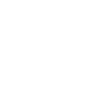

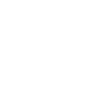

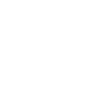

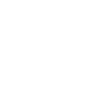

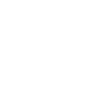

In [58]:
shapely_geoms = {}
for index, _geom in zip(row_indices, geoms):
    shapely_geom = shapely_from_wkb(_geom)
    shapely_geoms[index] = shapely_geom
    display(shapely_geom)

Hmm, interesting. It may or may not be obvious which of these is our building of interest, but either way let's treat this as a problem to solve robustly. We've done really inexpensive bounding box comparisons up until now to filter down the set of possibilities as cheaply as possible. Now that we have some actual contenders, we should switch to the more expensive comparison of the geometries themselves.

To facilitate this comparison, let's also load our geometry into shapely.

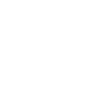

In [59]:
our_geom = shapely_from_geojson(json.dumps(geom))
display(our_geom)

With shapely geometries on either side, we can find all geometries that intersect our geometry.

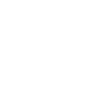

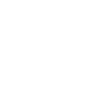

In [60]:
for _geom in shapely_geoms.values():
    if _geom.intersects(our_geom):
        display(_geom)

Hmm, well, we've narrowed it down. But still, we need to do better. How can we estimate similarity? Perhaps if we calculate the actual intersection as a geometry, we could measure its area? The larger the intersecting area, the more likely the geometry is our target building? After all, we might expect some overlaps around the edges that could cause intersecting slivers, but we should not have buildings overlapping in the Overture dataset.

So let's try that out and see what happens.

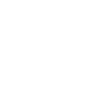

The row that most intersects our geometry is 18863 of row group 238 in https://overturemaps-us-west-2.s3.us-west-2.amazonaws.com/release/2026-10-21.0/theme=buildings/type=building/part-00033-113561ff-40a3-5f43-94b9-66b5c747af23-c000.zstd.parquet


In [61]:
max_intersection_area = 0
max_intersecting_geom = None
max_intersecting_index = None

for index, _geom in shapely_geoms.items():
    area = intersection(_geom, our_geom).area
    if area > max_intersection_area:
        max_intersection_area = area
        max_intersecting_geom = _geom
        max_intersecting_index = index

display(max_intersecting_geom)
print(
    f'The row that most intersects our geometry is {max_intersecting_index} of row group {row_group_index} in {file_url}'
)

Look at that! We've narrowed it down to a single row. Does this look like it is the right row?

## Questions

* How effective was parquet's support for predicate pushdown in our search? Can the access efficiency be quantified for this particular scenario?
* Using what you learned through this exercise, can you classify what types of problems parquet supports well?
* What about what parquet would be bad at? What are the trade-offs of parquet? What might be done to mitigate its trade-offs? What cannot be mitigated?
* Is parquet a true cloud-native format? Some argue that it is not. Can you make a case for why it is? What about why it might not be?
* What would it take to write a generic client for this access pattern? What about others? What would it take to make a truly general purpose query engine for parquet?